# Portfolio Allocation Project — Part 3: Rolling-Window Backtest

**Goal:** Part 2 tested the minimum-variance portfolio on single years (2008, 2020, 2022, 2025). Here we replace that single split with a **rolling backtest** that mimics how the strategy would actually be run. At the end of every month we:

1. take the last **3 years** of daily returns,
2. estimate $\hat\Sigma$ and compute the minimum-variance weights,
3. hold those weights during the **next** month.

Stitching all the months together gives one continuous **out-of-sample** record of almost 19 years, from February 2008 to October 2026, which covers the 2008 financial crisis, the long period of low interest rates that followed, the COVID crash and the 2022 inflation shock.

**Structure:**

| Section | Content |
|---|---|
| 1–2 | Data and the functions from Part 2 |
| 3–4 | Rebalancing dates and the estimation window (how we avoid look-ahead) |
| 5–6 | The backtest loop, the 1/N benchmark and the risk-free rate |
| 7 | Performance metrics (including Sharpe ratios) and growth of $1 |
| 8 | How the weights move over time |
| 9 | Turnover and trading costs |
| 10 | No-trade band: rebalancing only when the weights change enough |
| 11 | Leveraged minimum variance (same risk as 1/N) |
| 12 | Conclusions |

**Input:** `returns.csv` from Part 1 (daily log returns, one column per asset). Section 6 also uses the 3-month T-bill rate, downloaded once and saved to `risk_free.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRADING_DAYS = 252
EST_DAYS = 3 * TRADING_DAYS   # 3-year estimation window = 756 trading days

## 1. Load the returns

In [2]:
returns = pd.read_csv("returns.csv", index_col=0, parse_dates=True)
tickers = list(returns.columns)
K = len(tickers)
print(f"{returns.shape[0]} days x {K} assets, from {returns.index[0].date()} to {returns.index[-1].date()}")

5490 days x 9 assets, from 2005-01-04 to 2026-10-29


## 2. Tools from Part 2

The same two functions written in Part 2:

- `min_variance_weights(Sigma)` solves $\Sigma\mathbf x = \boldsymbol\iota$ and normalizes $\mathbf x$ so the weights add up to 1. The backtest calls it once per month.
- `performance(port_returns)` computes the annualized return, volatility, return/volatility ratio and maximum drawdown of a series of daily log returns.

In [3]:
def min_variance_weights(Sigma):
    """Minimum-variance weights (shorting allowed) for a covariance matrix Sigma."""
    iota = np.ones(Sigma.shape[0])
    x = np.linalg.solve(Sigma, iota)
    return x / x.sum()


def performance(port_returns):
    """Annualized metrics for a Series of daily portfolio log returns."""
    ann_return = port_returns.mean() * TRADING_DAYS
    ann_volatility = port_returns.std() * np.sqrt(TRADING_DAYS)
    value = np.exp(port_returns.cumsum())
    drawdown = value / value.cummax() - 1
    return pd.Series({
        "ann_return": ann_return,
        "ann_volatility": ann_volatility,
        "return_over_vol": ann_return / ann_volatility,
        "max_drawdown": drawdown.min(),
    })

## 3. Rebalancing dates

We rebalance at the close of the **last trading day of each month** (for example 29 March 2019, because the 30th and 31st fell on a weekend). Two conditions apply:

- The date needs a **full 3-year window** behind it: at least `EST_DAYS` trading days of history, counting the date itself. If a date sits at position $p$ (counting from 0), it has $p + 1$ days up to and including it, so we need $p \ge$ `EST_DAYS` $- 1$.
- The **last** month-end in the data (29 October 2026) is also the last day of data, so there is nothing left to hold after it. We drop it.

The returns start on 4 January 2005, so the first full window ends on **31 January 2008**, giving 225 monthly rebalances.

In [4]:
# Last trading day of each month
month_ends = returns.index.to_series().groupby(returns.index.to_period("M")).max()

# Keep the month-ends with a full 3-year window behind them
eligible = [t for t in month_ends if returns.index.get_loc(t) >= EST_DAYS - 1]

# Drop the last one: it is the last day of data, so there is nothing to hold after it
rebalance_dates = pd.DatetimeIndex(eligible[:-1])

print(f"{len(rebalance_dates)} rebalances, from {rebalance_dates[0].date()} to {rebalance_dates[-1].date()}")

225 rebalances, from 2008-01-31 to 2026-09-30


## 4. The estimation window (no look-ahead)

This is the step where backtests most often go wrong. At a rebalance date $t$ we can only use information available **at the close of $t$**:

- **Estimation window (in-sample):** the last `EST_DAYS` rows of `returns` **ending at $t$** (included).
- **Holding period (out-of-sample):** the days **strictly after $t$**, up to the next rebalance date (included).

```
        estimation window (756 days)           holding period
 |---------------------------------------| t |-------------| t_next
```

If the window included even one day after $t$, the weights would "know the future" and the results would be too good to be true. Each of the 225 windows is therefore a different in-sample period: the first runs from early 2005 to January 2008, and the last from roughly October 2023 to 30 September 2026.

In [5]:
def estimation_window(t):
    """The EST_DAYS rows of returns ending at date t (included)."""
    p = returns.index.get_loc(t)
    window = returns.iloc[p - EST_DAYS + 1 : p + 1]   # .iloc excludes the end, so p + 1 keeps row p
    return window

## 5. The backtest loop

For each rebalance date $t_i$:

1. Estimate $\hat\Sigma$ on `estimation_window(t_i)` and compute the minimum-variance weights.
2. Store the weights, to study them in section 8.
3. Find the holding period: the days after $t_i$ up to $t_{i+1}$. For the **last** rebalance, hold until the last day of data.
4. Compute the portfolio's daily returns in the holding period (`hold @ a`) and store them.

At the end, `pd.concat` joins the 225 monthly pieces into one continuous series of daily returns.

*Simplification (same as Part 2):* within each month the weights stay fixed, which implicitly assumes daily rebalancing back to them.

In [6]:
weights_history = {}   # rebalance date -> weights
monthly_pieces = []    # one Series of daily portfolio returns per holding period

for i, t in enumerate(rebalance_dates):
    # 1. Weights estimated only with data up to t
    a = min_variance_weights(estimation_window(t).cov().to_numpy())

    # 2. Store them
    weights_history[t] = a

    # 3. Holding period: from the day after t to the next rebalance (or the end of the data)
    hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
    hold = returns.loc[(returns.index > t) & (returns.index <= hold_end)]

    # 4. Portfolio returns for this month
    monthly_pieces.append(hold @ a)

weights_mv = pd.DataFrame(weights_history, index=tickers).T   # one row per rebalance date
mv_returns = pd.concat(monthly_pieces)
print(f"Out-of-sample: {mv_returns.index[0].date()} to {mv_returns.index[-1].date()}  ({len(mv_returns)} days)")

Out-of-sample: 2008-02-01 to 2026-10-29  (4716 days)


## 6. The 1/N benchmark and the risk-free rate

The equal-weight portfolio puts 1/9 (about 11.1%) in each asset and needs no estimation. To compare fairly, it must cover **exactly the same days** as the backtest. Its weights never change, so it has no turnover beyond keeping each asset at 1/9.

In [7]:
a_ew = np.ones(K) / K
ew_returns = returns.loc[mv_returns.index] @ a_ew

backtest = pd.DataFrame({"min_variance": mv_returns, "equal_weight": ew_returns})

**The risk-free rate and the Sharpe ratio.** A ratio like return/volatility ignores that investors can earn a return with no risk at all by holding Treasury bills. The **Sharpe ratio** measures the return **above the risk-free rate** per unit of risk:

$$\text{Sharpe} = \frac{\text{mean}(R_t - r_{f,t})}{\text{std}(R_t - r_{f,t})} \times \sqrt{252}$$

We use the **3-month U.S. Treasury bill rate** (`^IRX` on Yahoo Finance, an annualized yield in percent) as the risk-free rate. As with the prices in Part 1, it is downloaded once and then loaded from `risk_free.csv`. The excess return is computed on **simple** returns ($e^{r} - 1$), since the T-bill rate is a simple rate.

In [8]:
import os
import yfinance as yf

RF_FILE = "risk_free.csv"

if os.path.exists(RF_FILE):
    irx = pd.read_csv(RF_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    print("Loaded the risk-free rate from file.")
else:
    raw = yf.download("^IRX", start=returns.index[0], end=returns.index[-1] + pd.Timedelta(days=1),
                      auto_adjust=True, progress=False)
    irx = raw["Close"].iloc[:, 0]
    irx.to_csv(RF_FILE)
    print("Downloaded and saved the risk-free rate.")

# ^IRX is the annualized 13-week T-bill yield in percent -> daily rate
rf_daily = (irx / 100 / TRADING_DAYS).reindex(returns.index).ffill()
rf_bt = rf_daily.loc[backtest.index]
print(f"Average T-bill rate over the backtest: {rf_bt.mean() * TRADING_DAYS:.2%}")


def sharpe_ratio(log_returns, rf):
    """Annualized Sharpe ratio from daily log returns and a daily risk-free rate."""
    excess = np.exp(log_returns) - 1 - rf
    return excess.mean() / excess.std() * np.sqrt(TRADING_DAYS)

Loaded the risk-free rate from file.
Average T-bill rate over the backtest: 1.40%


## 7. Results: metrics and growth of $1

In [9]:
results = pd.DataFrame({name: performance(backtest[name]) for name in backtest})
results.loc["sharpe_ratio"] = [sharpe_ratio(backtest[name], rf_bt) for name in backtest]
results.round(4)

,min_variance,equal_weight
ann_return,0.0346,0.0566
ann_volatility,0.0454,0.1287
return_over_vol,0.7627,0.4397
max_drawdown,-0.1386,-0.3719
sharpe_ratio,0.4770,0.3956


**Reading the table**

- **Risk:** minimum variance kept its main promise over the whole period. Its volatility was 4.54% vs 12.87% for 1/N (about 65% lower), and its worst fall was −13.9% vs −37.2%. This is consistent with the single test years of Part 2 (3.6%–9.7% vs 10.6%–28.3%).
- **Return:** 1/N earned more (5.66% vs 3.46% per year). The minimum-variance portfolio is essentially a Treasury portfolio (see section 8), so it carries bond-like risk and earns bond-like returns. Over the whole period it still earned well above 3-month T-bills, which paid only 1.40% on average because rates were near zero for most of 2009–2021.
- **Efficiency:** over the full backtest, minimum variance had the **better** risk-adjusted performance: a Sharpe ratio of 0.48 vs 0.40 for 1/N (and a return/volatility ratio of 0.76 vs 0.44). It earned less, but took far less risk to earn it. As the subperiod table below shows, this advantage depends heavily on the interest-rate regime.

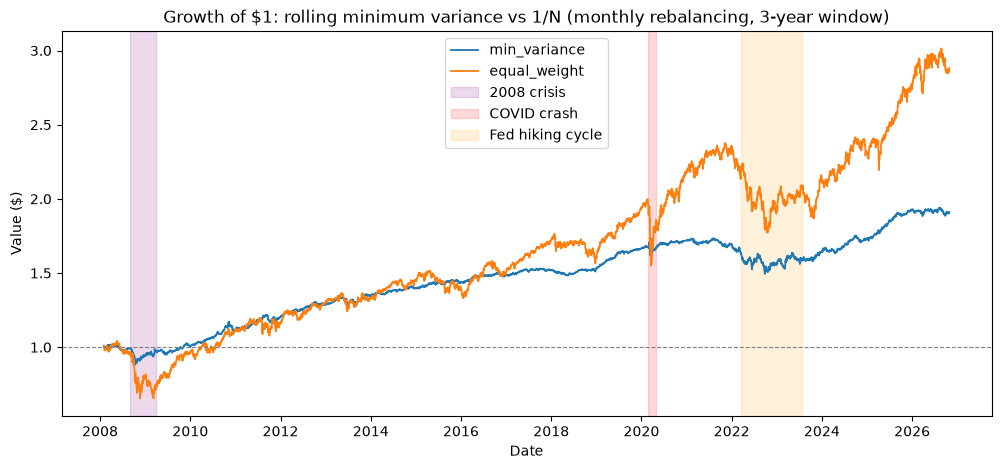

In [10]:
growth = np.exp(backtest.cumsum())

fig, ax = plt.subplots(figsize=(12, 5))
for name in growth.columns:
    ax.plot(growth.index, growth[name], label=name, linewidth=1.3)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")

ax.axvspan(pd.Timestamp("2008-09-01"), pd.Timestamp("2009-03-31"),
           color="purple", alpha=0.15, label="2008 crisis")
ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"),
           color="red", alpha=0.15, label="COVID crash")
ax.axvspan(pd.Timestamp("2022-03-16"), pd.Timestamp("2023-07-26"),
           color="orange", alpha=0.15, label="Fed hiking cycle")

ax.set_title("Growth of $1: rolling minimum variance vs 1/N (monthly rebalancing, 3-year window)")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend()
plt.show()

**Reading the chart**

- **$1 grows to about $1.91 with minimum variance and $2.88 with 1/N.**
- **2008 crisis:** 1/N fell 37.2% from May to November 2008, while minimum variance's worst fall was 13.3% and it recovered by the end of 2009. Over calendar 2008 it lost about 6%, against 21% for 1/N.
- **2010–2019:** the two strategies followed almost the same path, but minimum variance did it with about a third of the volatility. This is where its Sharpe ratio advantage comes from.
- **The gap opens after 2019:** 1/N pulled ahead in the strong equity years (2019, 2020's recovery, 2023–2025). During the COVID crash itself minimum variance barely moved, while 1/N fell sharply.
- **Fed hiking cycle:** this is where minimum variance had its **worst fall of the whole backtest** (−13.9% from August 2021 to September 2022), because rising rates hit its large Treasury position. 1/N also fell (−24.5% in 2022), but its worst fall remains 2008. Minimum variance protected very well against growth shocks (2008, COVID), but much less against the inflation shock.

**Two regimes.** The full-sample numbers hide a sharp break. The table below splits the backtest into **2008–2021** (falling and near-zero interest rates, negative stock–bond correlation) and **2022–2026** (inflation and rising rates, positive stock–bond correlation), the two regimes identified in Part 1.

In [11]:
periods = {"2008–2021": ("2008", "2021"), "2022–2026": ("2022", "2026")}

rows = {}
for label, (start, end) in periods.items():
    rf_p = rf_bt.loc[start:end]
    for name in backtest:
        r_p = backtest[name].loc[start:end]
        rows[(label, name)] = pd.Series({
            "ann_return": r_p.mean() * TRADING_DAYS,
            "ann_volatility": r_p.std() * np.sqrt(TRADING_DAYS),
            "sharpe_ratio": sharpe_ratio(r_p, rf_p),
            "avg_tbill_rate": rf_p.mean() * TRADING_DAYS,
        })
pd.DataFrame(rows).T.round(4)

ann_return  ann_volatility  sharpe_ratio  \
2008–2021 min_variance      0.0377          0.0425        0.7869   
          equal_weight      0.0616          0.1329        0.4918   
2022–2026 min_variance      0.0257          0.0528       -0.2364   
          equal_weight      0.0420          0.1156        0.0789   

                        avg_tbill_rate  
2008–2021 min_variance          0.0051  
          equal_weight          0.0051  
2022–2026 min_variance          0.0396  
          equal_weight          0.0396

**Reading the two regimes**

- **2008–2021: minimum variance was clearly better.** Sharpe ratio of 0.79 vs 0.49 for 1/N. Falling yields pushed Treasury prices up, T-bills paid almost nothing (0.5% on average), and Treasuries hedged stocks in every crisis.
- **2022–2026: the opposite.** Minimum variance's Sharpe ratio was −0.24 (it earned less than T-bills, which paid about 4% on average), while 1/N's was slightly positive (0.08). Rising rates hit its Treasury positions and the stock–bond correlation turned positive.
- **The sample decides the verdict.** A backtest starting in 2019 would show minimum variance with a Sharpe ratio of about 0 against about 0.40 for 1/N; one starting in 2008 shows the opposite ranking. Any conclusion about which strategy is "better" depends on which regime dominates the sample.

## 8. How the weights move over time

The four assets with the largest positions are highlighted; the other five are drawn in gray. The lower panel shows the **total short position** (the sum of the negative weights), which is the amount a broker would have to lend.

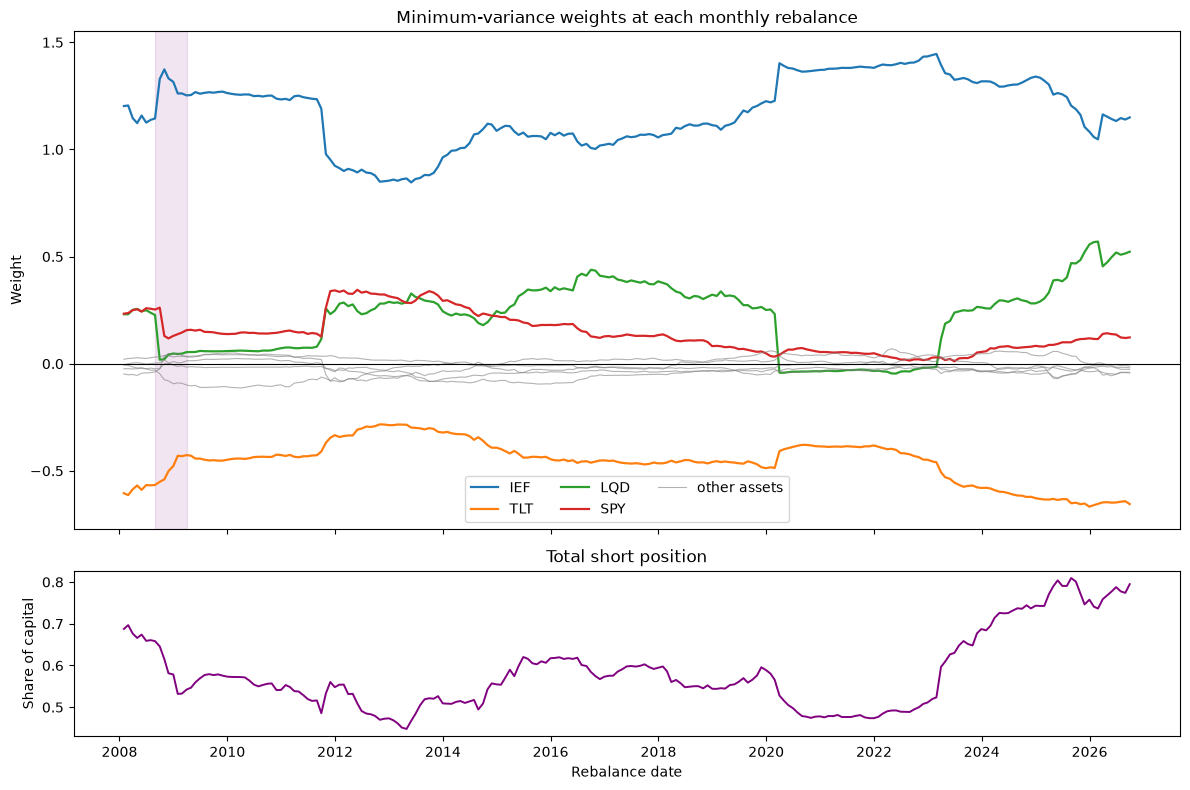

Average weights over the backtest:
SPY    0.143
IWM   -0.006
EFA   -0.020
EEM   -0.011
TLT   -0.456
IEF    1.174
LQD    0.219
GLD   -0.004
VNQ   -0.039
dtype: float64


In [12]:
main_assets = ["IEF", "TLT", "LQD", "SPY"]
other_assets = [t for t in tickers if t not in main_assets]
total_short = -weights_mv[weights_mv < 0].sum(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

for name in main_assets:
    ax1.plot(weights_mv.index, weights_mv[name], label=name, linewidth=1.6)
for j, name in enumerate(other_assets):
    ax1.plot(weights_mv.index, weights_mv[name], color="gray", linewidth=0.8,
             alpha=0.6, label="other assets" if j == 0 else None)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_title("Minimum-variance weights at each monthly rebalance")
ax1.set_ylabel("Weight")
ax1.axvspan(pd.Timestamp("2008-09-01"), pd.Timestamp("2009-03-31"), color="purple", alpha=0.1)
ax1.legend(ncol=3)

ax2.plot(total_short.index, total_short, color="purple", linewidth=1.4)
ax2.set_title("Total short position")
ax2.set_ylabel("Share of capital")
ax2.set_xlabel("Rebalance date")

plt.tight_layout()
plt.show()

print("Average weights over the backtest:")
print(weights_mv.mean().round(3))

**Reading the weights**

- **The portfolio is built around a Treasury pair:** IEF between 85% and 145% (117% on average), financed largely by a TLT short between −28% and −67% (−46% on average). This is the hedge example from Part 2 at work every month: two highly correlated assets with different volatilities.
- **The pair stays stable:** the long IEF / short TLT structure is present in all 225 months, so the strategy's results depend heavily on how intermediate and long Treasuries behave relative to each other.
- **Corporate bonds come and go with the crises:** LQD averages 22% but swings from about −5% to 57%. It drops to around 2%–7% from September 2008 to late 2011, while the 2008 crisis (when LQD had its most extreme days) is inside the 3-year window, and again to roughly zero from March 2020 to March 2023, while the COVID crash is inside it. Each time the crisis leaves the window, LQD looks safe again and its weight recovers, reaching about 50% by 2026.
- **Equities are the second building block:** SPY averages 14% (between 1% and 34%), with its largest weights in 2012–2013 and its smallest in 2021–2023. The other risky assets get small positions, mostly short.
- **Leverage is high and persistent:** the total short position stays between 45% and 81% of capital (58% on average), so gross exposure is about 1.9–2.6 times capital.

## 9. Turnover and trading costs

At each rebalance, **turnover** measures how much of the portfolio is traded:

$$\text{turnover}_t = \sum_k |a_{k,t} - a_{k,t-1}|$$

If trading costs $c$ per dollar traded (bid-ask spread plus commissions), the cost of that rebalance is $c \times \text{turnover}_t$. For very liquid ETFs like ours, $c$ is roughly 2–10 basis points (0.02%–0.10%).

*Simplification:* we compare each month's target weights with the previous month's target weights, and ignore how the weights drift with prices during the month.

In [13]:
turnover = weights_mv.diff().abs().sum(axis=1).iloc[1:]   # the first rebalance has nothing before it

avg_monthly = turnover.mean()
annual_turnover = avg_monthly * 12
print(f"Average monthly turnover: {avg_monthly:.1%}  (median {turnover.median():.1%})")
print(f"Annual turnover:          {annual_turnover:.1%}")
print()

mv_annual_return = performance(mv_returns)["ann_return"]
for c in [0.0002, 0.0005, 0.0010]:
    cost = annual_turnover * c
    print(f"Cost of {c * 1e4:.0f} bp per dollar traded -> {cost:.3%} per year "
          f"({cost / mv_annual_return:.1%} of the annual return)")

Average monthly turnover: 5.8%  (median 3.8%)
Annual turnover:          69.7%

Cost of 2 bp per dollar traded -> 0.014% per year (0.4% of the annual return)
Cost of 5 bp per dollar traded -> 0.035% per year (1.0% of the annual return)
Cost of 10 bp per dollar traded -> 0.070% per year (2.0% of the annual return)


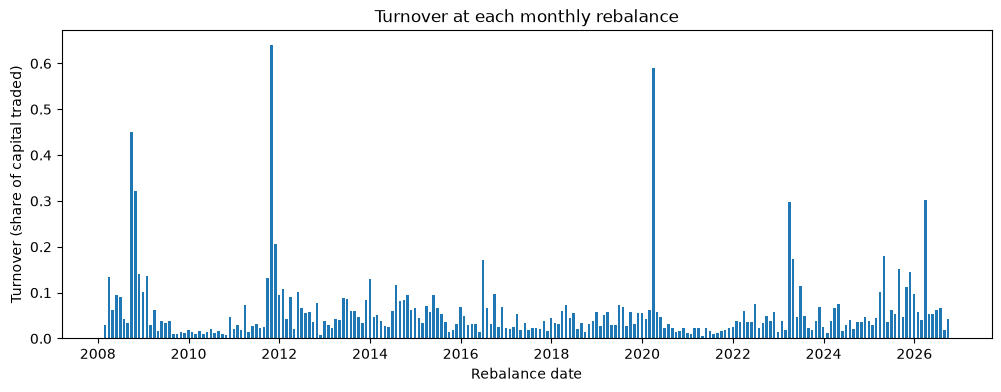

Largest rebalances:
2011-10-31    0.640
2020-03-31    0.590
2008-09-30    0.451
2008-10-31    0.322
2026-03-31    0.303
dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(turnover.index, turnover.values, width=20)
ax.set_title("Turnover at each monthly rebalance")
ax.set_xlabel("Rebalance date")
ax.set_ylabel("Turnover (share of capital traded)")
plt.show()

print("Largest rebalances:")
print(turnover.sort_values(ascending=False).head(5).round(3))

**Reading the turnover**

- **A typical month trades little:** the median turnover is 3.8% of capital, because each month only 1 of the 36 months in the window changes, so $\hat\Sigma$ moves slowly. The annual turnover is about 70%.
- **Costs are negligible:** even at 10 basis points, trading costs are below 0.1% per year. They don't change any conclusion. The borrow fee on the short positions (Part 2) matters more than trading costs.
- **Turnover spikes when extreme days enter or leave the window.** The 2008 crisis entered the window in September–October 2008 (45% and 32% of capital traded) and left it exactly three years later, in October–November 2011 (64%, the largest rebalance of the backtest, and 21%). The COVID crash did the same: it entered in March 2020 (59%) and left in March 2023 (30%). This is a known side effect of a fixed-length rolling window: one extreme episode moves the weights twice. An EWMA estimator, which fades old data gradually instead of dropping it all at once, would smooth these jumps.

## 10. Extension: no-trade band

**Rule:** at each month-end, compute the new target weights, but **only trade if**

$$\sum_k |a_{k,\text{new}} - a_{k,\text{current}}| > \text{threshold}$$

Otherwise, keep the current weights for another month. The idea is to avoid trading on small changes that are mostly estimation noise, and to save trading costs.

The loop is the same as in section 5, with one difference: it keeps a variable with the **current** weights and only replaces it when the change is large enough. With a threshold of 0, it trades every month and reproduces section 5 exactly.

In [15]:
def backtest_with_threshold(threshold):
    """Rolling min-variance backtest that only rebalances when the change in weights exceeds threshold.

    Returns (daily returns Series, number of trades, total turnover).
    """
    a_current = None
    n_trades = 0
    total_turnover = 0.0
    pieces = []

    for i, t in enumerate(rebalance_dates):
        a_new = min_variance_weights(estimation_window(t).cov().to_numpy())

        if a_current is None:
            # First month: open the initial position
            a_current = a_new
            n_trades += 1
        else:
            change = np.abs(a_new - a_current).sum()
            if change > threshold:
                total_turnover += change
                a_current = a_new
                n_trades += 1

        hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
        hold = returns.loc[(returns.index > t) & (returns.index <= hold_end)]
        pieces.append(hold @ a_current)

    return pd.concat(pieces), n_trades, total_turnover

In [16]:
years = len(mv_returns) / TRADING_DAYS
COST = 0.0005   # 5 basis points per dollar traded

rows = {}
for threshold in [0.0, 0.05, 0.10, 0.20]:
    r_th, n_trades, total_turnover = backtest_with_threshold(threshold)
    rows[f"{threshold:.0%}"] = pd.concat([
        pd.Series({
            "n_trades": n_trades,
            "annual_turnover": total_turnover / years,
            "annual_cost_5bp": total_turnover / years * COST,
        }),
        performance(r_th),
    ])

threshold_table = pd.DataFrame(rows).T
threshold_table.index.name = "threshold"
threshold_table.round(4)

,n_trades,annual_turnover,annual_cost_5bp,ann_return,ann_volatility,return_over_vol,max_drawdown
threshold,,,,,,,
0%,225.0,0.6956,0.0003,0.0346,0.0454,0.7627,-0.1386
5%,114.0,0.5977,0.0003,0.0347,0.0454,0.7638,-0.1380
10%,57.0,0.5038,0.0003,0.0345,0.0459,0.7528,-0.1377
20%,29.0,0.4171,0.0002,0.0349,0.0462,0.7563,-0.1382


**Reading the no-trade band**

- **It cuts trading a lot:** with a 10% threshold the portfolio trades 57 times instead of 225, and with 20% only 29 times. Annual turnover falls from about 70% to 42%.
- **Risk barely changes:** volatility stays between 4.5% and 4.6% and the maximum drawdown at about −13.8% for every threshold. Skipping small rebalances does not let the risk drift in a meaningful way.
- **But the savings are tiny:** at 5 basis points, the trading cost falls from about 0.03% to 0.02% per year. The differences in return between thresholds (3.45%–3.49%) are of the same order and mostly noise.
- **Conclusion:** the band works as intended (fewer trades, same risk), but with liquid ETFs the cost it saves is too small to matter. It would matter more with less liquid assets, higher trading costs, taxes on realized gains, or a shorter estimation window, which makes the weights move more.

## 11. Leveraged minimum variance

Minimum variance takes much less risk than 1/N, so comparing their returns directly is not entirely fair. A classic argument says: if minimum variance had a better risk/return trade-off, you could **borrow money to leverage it** up to the same volatility as 1/N, and then it would earn more. This section tests that idea.

**Leverage without look-ahead.** Using the final realized volatilities (4.54% vs 12.87%) to choose the leverage would use information from the future. Instead, at each rebalance date we set

$$L_t = \frac{\hat\sigma_{1/N,t}}{\hat\sigma_{MV,t}}$$

where both volatilities are estimated on the same 3-year window used for the weights. During the following month we hold $L_t$ times the minimum-variance portfolio.

**Financing cost.** Leverage means borrowing $L_t - 1$ for every dollar of capital, and the borrowed money pays interest. We use the T-bill rate from section 6 as the borrowing rate. This is optimistic: real investors borrow at a higher rate, and they also pay a borrow fee on short positions. The end of this section measures how much these two costs change the result.

**What to expect.** Borrowing or lending at the risk-free rate scales both the excess return and the volatility by the same factor, so **leverage does not change the Sharpe ratio**. Leverage only helps if the strategy has a positive Sharpe ratio, higher than the benchmark's. Section 7 showed that over the full backtest minimum variance had a higher Sharpe ratio than 1/N (0.48 vs 0.40), so leverage should give it a higher return at the same risk. This section checks whether that happens in practice, and what leverage does to the drawdowns in each regime.

*Technical note:* leverage and interest are applied to **simple** returns ($e^{r} - 1$), not log returns, because a leveraged position's daily gain is $L$ times the simple return minus the interest on the loan.

In [17]:
# Leverage at each rebalance: estimated 1/N volatility / estimated min-variance volatility (same window)
leverage = {}
for t in rebalance_dates:
    Sigma_t = estimation_window(t).cov().to_numpy()
    a_t = weights_mv.loc[t].to_numpy()
    leverage[t] = np.sqrt(a_ew @ Sigma_t @ a_ew) / np.sqrt(a_t @ Sigma_t @ a_t)
leverage = pd.Series(leverage)

# Each day uses the leverage chosen at the previous rebalance (same holding periods as section 5)
lev_pieces = []
for i, t in enumerate(rebalance_dates):
    hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
    days = backtest.index[(backtest.index > t) & (backtest.index <= hold_end)]
    lev_pieces.append(pd.Series(leverage[t], index=days))
lev_daily = pd.concat(lev_pieces)

print(f"Leverage: average {leverage.mean():.2f}x, from {leverage.min():.2f}x to {leverage.max():.2f}x")

Leverage: average 3.16x, from 1.99x to 4.87x


In [18]:
simple = np.exp(backtest) - 1            # log returns -> simple returns

# Leveraged min variance: L times the portfolio, minus interest on the borrowed (L - 1)
simple["mv_levered"] = lev_daily * simple["min_variance"] - (lev_daily - 1) * rf_bt

# Reference only (uses look-ahead): one constant leverage that matches 1/N's realized volatility exactly
L_ex_post = simple["equal_weight"].std() / simple["min_variance"].std()
simple["mv_levered_ex_post"] = L_ex_post * simple["min_variance"] - (L_ex_post - 1) * rf_bt
print(f"Ex-post constant leverage: {L_ex_post:.2f}x")


def performance_rf(simple_returns, rf):
    """Annualized metrics, including the Sharpe ratio, for a Series of daily simple returns."""
    excess = simple_returns - rf
    value = (1 + simple_returns).cumprod()
    drawdown = value / value.cummax() - 1
    return pd.Series({
        "ann_return": np.log1p(simple_returns).mean() * TRADING_DAYS,
        "ann_volatility": simple_returns.std() * np.sqrt(TRADING_DAYS),
        "sharpe_ratio": excess.mean() / excess.std() * np.sqrt(TRADING_DAYS),
        "max_drawdown": drawdown.min(),
        "final_value": value.iloc[-1],
    })


strategies = ["equal_weight", "min_variance", "mv_levered", "mv_levered_ex_post"]
pd.DataFrame({name: performance_rf(simple[name], rf_bt) for name in strategies}).round(4)

Ex-post constant leverage: 2.83x


,equal_weight,min_variance,mv_levered,mv_levered_ex_post
ann_return,0.0566,0.0346,0.0724,0.0670
ann_volatility,0.1286,0.0454,0.1517,0.1286
sharpe_ratio,0.3956,0.4770,0.4605,0.4770
max_drawdown,-0.3719,-0.1386,-0.4677,-0.3635
final_value,2.8827,1.9107,3.8730,3.5064


The same comparison, split into the two interest-rate regimes:

In [19]:
rows = {}
for label, (start, end) in periods.items():
    for name in ["equal_weight", "min_variance", "mv_levered"]:
        rows[(label, name)] = performance_rf(simple[name].loc[start:end], rf_bt.loc[start:end])
pd.DataFrame(rows).T.round(4)

ann_return  ann_volatility  sharpe_ratio  \
2008–2021 equal_weight      0.0616          0.1327        0.4918   
          min_variance      0.0377          0.0425        0.7869   
          mv_levered        0.1101          0.1503        0.7736   
2022–2026 equal_weight      0.0420          0.1157        0.0789   
          min_variance      0.0257          0.0529       -0.2364   
          mv_levered       -0.0369          0.1556       -0.4142   

                        max_drawdown  final_value  
2008–2021 equal_weight       -0.3719       2.3556  
          min_variance       -0.1330       1.6887  
          mv_levered         -0.4038       4.6254  
2022–2026 equal_weight       -0.2446       1.2238  
          min_variance       -0.1147       1.1315  
          mv_levered         -0.3918       0.8373

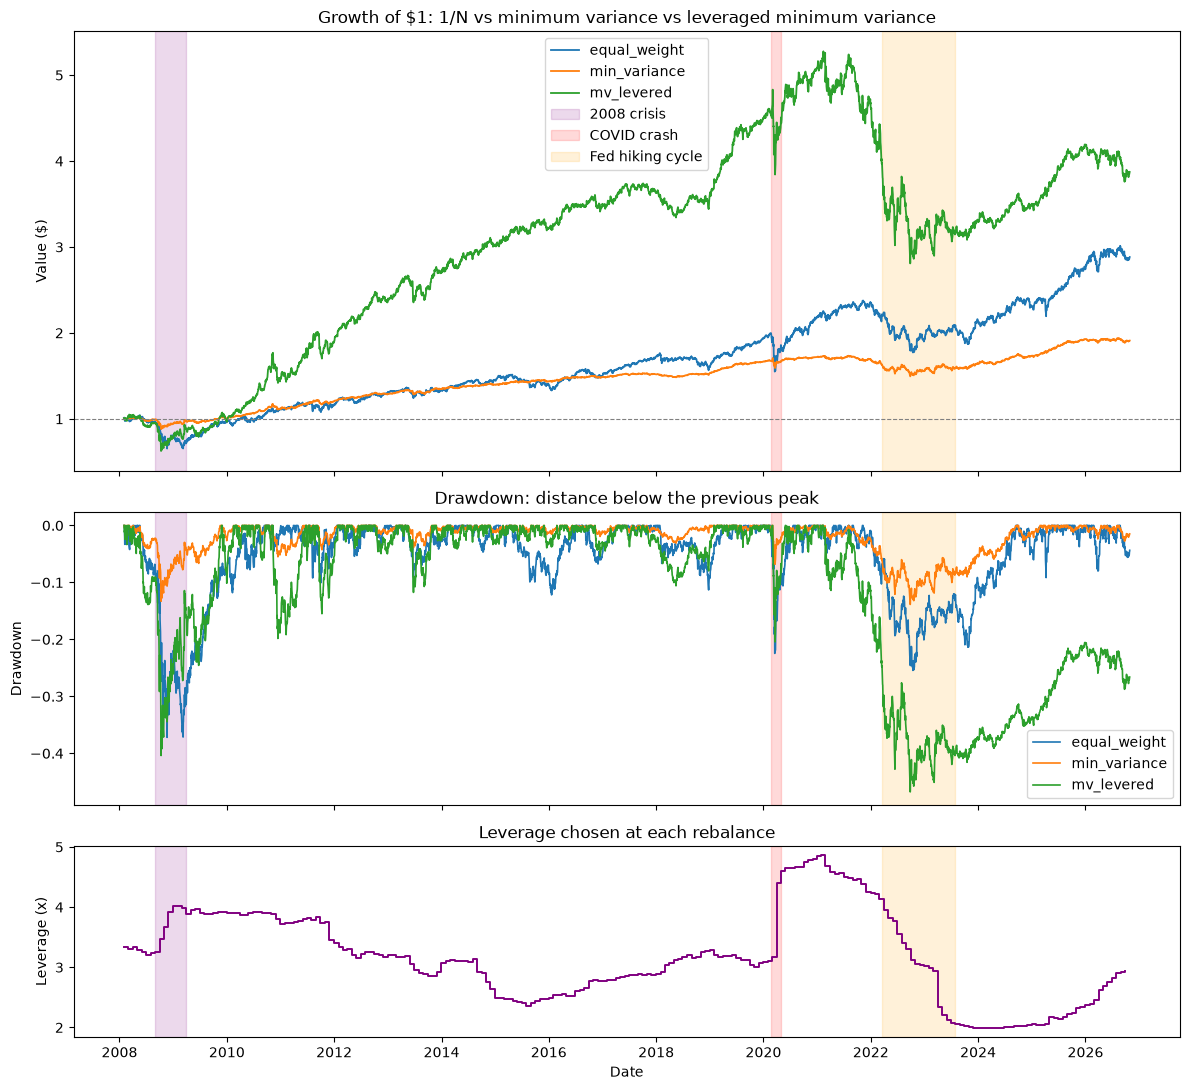

In [20]:
value = (1 + simple[["equal_weight", "min_variance", "mv_levered"]]).cumprod()
drawdown = value / value.cummax() - 1

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 11), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 2, 1.3]})

for name in value.columns:
    ax1.plot(value.index, value[name], label=name, linewidth=1.3)
    ax2.plot(drawdown.index, drawdown[name], label=name, linewidth=1.2)
ax1.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax1.set_title("Growth of $1: 1/N vs minimum variance vs leveraged minimum variance")
ax1.set_ylabel("Value ($)")
ax2.set_title("Drawdown: distance below the previous peak")
ax2.set_ylabel("Drawdown")

ax3.plot(leverage.index, leverage, color="purple", linewidth=1.4, drawstyle="steps-post")
ax3.set_title("Leverage chosen at each rebalance")
ax3.set_ylabel("Leverage (x)")
ax3.set_xlabel("Date")

for ax in (ax1, ax2, ax3):
    ax.axvspan(pd.Timestamp("2008-09-01"), pd.Timestamp("2009-03-31"), color="purple", alpha=0.15,
               label="2008 crisis" if ax is ax1 else None)
    ax.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30"), color="red", alpha=0.15,
               label="COVID crash" if ax is ax1 else None)
    ax.axvspan(pd.Timestamp("2022-03-16"), pd.Timestamp("2023-07-26"), color="orange", alpha=0.15,
               label="Fed hiking cycle" if ax is ax1 else None)
ax1.legend()
ax2.legend()

plt.tight_layout()
plt.show()

**Reading the results**

- **Before realistic costs, leverage worked over the full backtest.** Financed at the T-bill rate, leveraged minimum variance earned 7.2% per year against 5.7% for 1/N, and $1 grew to $3.87 vs $2.88. With a higher Sharpe ratio to start with, borrowing to scale it up gave a higher return.
- **But the drawdowns were much deeper.** The leveraged portfolio lost about 40% in 2008 (March–October) and 47% from February 2021 to September 2022, against a worst fall of 37% for 1/N. At the end of the sample it was still about 27% below its 2021 peak, when it had reached about $5.2.
- **All the advantage came from 2008–2021.** In that regime the leveraged version earned 11.0% per year (Sharpe 0.77 vs 0.49 for 1/N). In 2022–2026 it lost 3.7% per year (Sharpe −0.41), while 1/N earned 4.2%. Leverage magnifies whichever regime you are in.
- **The leverage followed the crises.** It averaged 3.2x (between 2.0x and 4.9x) and was highest after a crisis entered the estimation window, because 1/N then looked very risky compared with minimum variance: about 3.9x in 2009–2011, which worked well as rates kept falling, and about 4.5–4.9x in 2020–2021, which left the portfolio at its largest leverage just before the 2022 rate shock.
- **The leverage overshot the target.** Realized volatility was 15.2%, above 1/N's 12.9%. The leverage is set from in-sample volatilities, which underestimate the real out-of-sample risk of minimum variance (the same effect seen in Part 2, where realized volatility was 2.7 to 3.3 times the in-sample estimate in 2008, 2020 and 2022).
- **With hindsight, the trade-off is clearer.** A constant leverage chosen after the fact to match 1/N's realized volatility exactly (2.83x) keeps minimum variance's Sharpe ratio (0.48), earns 6.7% per year and has a maximum drawdown of −36.4%, very close to 1/N's −37.2%. At equal risk, leveraged minimum variance would have earned about one percentage point more per year.
- **In practice it would be harder.** On top of the existing short positions, about 3x leverage means gross exposure of roughly 6 to 7 times capital. The cost sensitivity below shows that real borrowing costs change the conclusion.

**This is the risk-parity argument, with both of its sides.** Leveraging a low-risk, bond-heavy portfolio is the idea behind strategies like risk parity, which performed very well during the long fall in interest rates. This backtest shows that side (2008–2021) and the other one: when the regime changes and rates rise, the same leverage turns into one of the deepest drawdowns in the sample. The general rule holds in both: leverage scales risk and excess return together, so it only helps when the strategy's excess return is positive.

### How realistic borrowing costs change the result

The results above leave out two real costs, and leverage multiplies both:

- **Spread over the T-bill rate:** investors borrow at the T-bill rate plus a spread (typically 0.5%–1% or more). It is paid on the borrowed amount, $L_t - 1$ times capital.
- **Borrow fee on the short positions:** shorting an ETF costs an annual fee (often around 0.5% for Treasury ETFs). It is paid on the short positions, which leverage scales up to $L_t$ times the unleveraged short.

With a spread $s$ and a borrow fee $c$, the daily return of the leveraged portfolio becomes

$$R^{\text{lev}}_t = L_t\, R^{MV}_t \;-\; (L_t - 1)\left(r_{f,t} + \tfrac{s}{252}\right) \;-\; L_t\, \text{short}_t\, \tfrac{c}{252}$$

where $\text{short}_t$ is the total short position of the unleveraged portfolio.

In [21]:
# Total short position of the unleveraged portfolio during each holding period
short_pieces = []
for i, t in enumerate(rebalance_dates):
    hold_end = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else returns.index[-1]
    days = backtest.index[(backtest.index > t) & (backtest.index <= hold_end)]
    w_t = weights_mv.loc[t]
    short_pieces.append(pd.Series(-w_t[w_t < 0].sum(), index=days))
short_daily = pd.concat(short_pieces)

print(f"On average the leveraged portfolio borrows {(lev_daily - 1).mean():.1f}x its capital "
      f"and is short {(lev_daily * short_daily).mean():.1f}x its capital")

scenarios = {                                    # (spread over T-bills, borrow fee on shorts)
    "levered: T-bill rate only": (0.0, 0.0),
    "levered: +0.5% spread": (0.005, 0.0),
    "levered: +0.5% spread, 0.5% fee": (0.005, 0.005),
    "levered: +1% spread, 0.5% fee": (0.01, 0.005),
}

rows = {}
for name, (spread, fee) in scenarios.items():
    r_net = (lev_daily * simple["min_variance"]
             - (lev_daily - 1) * (rf_bt + spread / TRADING_DAYS)
             - lev_daily * short_daily * fee / TRADING_DAYS)
    rows[name] = performance_rf(r_net, rf_bt)

rows["unlevered: 0.5% fee"] = performance_rf(simple["min_variance"] - short_daily * 0.005 / TRADING_DAYS, rf_bt)
rows["1/N"] = performance_rf(simple["equal_weight"], rf_bt)
pd.DataFrame(rows).T.round(4)

On average the leveraged portfolio borrows 2.2x its capital and is short 1.8x its capital


,ann_return,ann_volatility,sharpe_ratio,max_drawdown,final_value
levered: T-bill rate only,0.0724,0.1517,0.4605,-0.4677,3.8730
levered: +0.5% spread,0.0615,0.1517,0.3892,-0.4813,3.1629
"levered: +0.5% spread, 0.5% fee",0.0525,0.1517,0.3300,-0.4897,2.6735
"levered: +1% spread, 0.5% fee",0.0417,0.1517,0.2587,-0.5027,2.1833
unlevered: 0.5% fee,0.0317,0.0454,0.4129,-0.1410,1.8095
1/N,0.0566,0.1286,0.3956,-0.3719,2.8827


**Reading the costs**

- **Leverage multiplies the costs.** On average the leveraged portfolio borrows about 2.2 times its capital and is short about 1.8 times its capital, so each 0.5% of cost takes roughly 1 percentage point off the annual return.
- **With realistic costs, the advantage over 1/N disappears.** A 0.5% spread alone brings the return down to 6.2% and the Sharpe ratio to 0.39, already slightly below 1/N (0.40). Adding a 0.5% borrow fee on the shorts brings it to 5.3% (Sharpe 0.33), and with a 1% spread to 4.2% (Sharpe 0.26), both below 1/N's 5.7%.
- **The costs also matter without leverage.** Unleveraged minimum variance with a 0.5% borrow fee on its shorts has a Sharpe ratio of 0.41, practically tied with 1/N.
- **Conclusion:** the higher Sharpe ratio of minimum variance in this sample is real but small, and it is about the same size as realistic financing costs. Turning it into a higher return through leverage only works if the investor can borrow and short very cheaply, as large institutions can.

## 12. Conclusions

1. **Risk.** Over almost 19 years of monthly out-of-sample rebalancing, minimum variance delivered much lower volatility than 1/N (4.5% vs 12.9%) and a much smaller worst fall (−13.9% vs −37.2%). It protected especially well in the 2008 crisis and the COVID crash, confirming the single-year results of Part 2.

2. **Return and efficiency.** 1/N earned more (5.7% vs 3.5% per year, so $1 became $2.88 vs $1.91), but over the full sample minimum variance had the better Sharpe ratio (0.48 vs 0.40). That advantage came entirely from 2008–2021 (0.79 vs 0.49); in 2022–2026, with rising rates and a positive stock–bond correlation, it reversed (−0.24 vs 0.08). The portfolio behaves like a leveraged Treasury position: it protected very well against growth shocks (2008, COVID) but had its worst loss in 2022, an inflation shock.

3. **Turnover and trading costs.** Re-estimating every month generates moderate turnover (about 70% per year, with spikes when a crisis enters or leaves the 3-year window, such as October 2008, October 2011, March 2020 and March 2023), but with liquid ETFs the trading cost is below 0.1% per year. It doesn't change the conclusions; the borrow fee on the 45%–81% short position is a larger cost.

4. **No-trade band.** Rebalancing only when the weights change by more than 10% or 20% cuts the number of trades by three quarters or more, without changing the risk of the portfolio. In this setting, the cost saved is negligible, so the band is a reasonable simplification rather than a source of performance.

5. **Leverage.** Leveraged to 1/N's volatility and financed at the T-bill rate, minimum variance earned more over the full sample (7.2% vs 5.7% per year), but with much deeper drawdowns (−40% in 2008 and −47% in 2021–2022) and only thanks to 2008–2021; in 2022–2026 it lost money. With realistic costs (a 0.5% spread over T-bills and a 0.5% borrow fee on the shorts), the return falls to 5.3% and the Sharpe ratio to 0.33, below 1/N. Leverage chosen from the estimation window also overshot the target volatility, because in-sample volatility underestimates real risk.

**Overall:** the verdict on minimum variance depends on the interest-rate regime. Over a period dominated by falling rates it was the more efficient strategy, but its advantage was small: realistic borrowing and shorting costs are enough to erase it, especially once leveraged. When rates rise, the advantage disappears even before costs. The length and composition of the sample matter as much as the method.

**Limitations and next steps**

- The strategy relies on large short positions, especially in TLT. A **long-only** version would be more realistic for many investors and is a natural comparison (Part 4).
- The **borrow fee** on the short positions and borrowing rates above the T-bill rate are only included as a sensitivity check in section 11; building them into the main results would make the comparison with 1/N more realistic.
- The covariance estimator could be improved with **EWMA** or **Ledoit-Wolf shrinkage**, and different window lengths (1, 2 or 5 years) could be compared, keeping in mind the regime change in the stock–bond correlation found in Part 1.